# NCAA BPM shared and leave-one-out roster pressure

This companion preserves the PPM notebook and its results. It asks whether the observed HERO patterns look different when we describe performance with **BPM**. It does not estimate a congestion effect or fit the selection model.

**Start here:** the rows are all available final-season players, the top performance band, and the adjacent band of the same width. `band_fraction` controls their width: .02 means top 2% and next 2%; .03 reproduces the bands in Entry 5 of our printable walkthrough. They are candidate performance bands, not validated “superstars” or a draft boundary.

BPM coverage restricts these plots to **2011–2021**. The original PPM window was 2009–2021. The new narrow-band rows also differ from the older draftee-college player-season cohorts. These differences mean this is not yet a controlled test that BPM outperforms PPM.

In [1]:
# Session: 2026-10-25 | BPM companion; notebook-edit waiver carried forward for this task.

## 1 Settings you can change

Change **gamma** or **theta_quantile**, set **REBUILD_FIGURES = True**, then Run All. Theta is recalculated from the full eligible available roster before selecting focal players. It does not change the top/next band membership.

`band_mode="top_next"` uses our latest narrow bands. `band_mode="historical"` restores the older cohort definitions on BPM: all-player final season, draftee-college player-seasons with BPM z from 2 to 3, and draftee-college player-seasons at or above the 93rd percentile of BPM z. Historical mode also uses a separate draftee-college standardization reference, as the old pipeline did.

`band_fraction` defines each performance band independently of theta. For example, .02 means top 2% and next 2%, while `theta_quantile=.98` separately sets the relevance threshold at the 98th percentile of eligible roster performance. Neither setting is fitted here.

**After changing settings, use Run All.** Rebuilding creates new image files, but already displayed output cells keep their previous images until those cells run again. Each display below reports its settings and run ID so older output can be identified.

In [2]:
SETTINGS = {
    "theta_quantile": 0.98,
    "gamma": 6.0,
    "n_bins": 16,
    "thin_n": 30,
    "band_mode": "top_next",       # "top_next" or "historical"
    "band_fraction": 0.02,         # Width of EACH band: .02 = top 2% and next 2%; independent of theta
    "show_squid_jackal": True,
}
REBUILD_FIGURES = True  # Saved BPM output is ready. Set True after changing settings.


## 2 Rebuild or load the matching saved run

The analysis checks the frozen source hashes and preserves the existing final-season identities. Missing focal BPM excludes that observation; it does not substitute an earlier season. Missing teammate BPM is omitted rather than set to zero. Means are computed on the available full eligible team-season roster before selecting a performance band. If leave-one-out pressure is undefined, that focal observation is excluded from both sides of the paired comparison.

Roster performance is BPM standardized within season, using the sample standard deviation. Competitive relevance is the sigmoid of gamma times that performance minus theta. Shared pressure averages relevance over the available roster; leave-one-out pressure averages over the other available members. Raw pooled BPM ranks define the default narrow bands, exactly as in Entry 5.

In [3]:
from pathlib import Path
import sys, importlib, json
import pandas as pd
from IPython.display import display, Image, FileLink
HERE = Path.cwd()
if not (HERE / "bpm_roster_pressure_analysis.py").exists():
    candidates = [HERE / "manuscript_figures/section_4_5/roster_pressure_comparison",
                  HERE / "3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/roster_pressure_comparison"]
    HERE = next((p for p in candidates if (p / "bpm_roster_pressure_analysis.py").exists()), None)
    if HERE is None:
        raise RuntimeError("Open this notebook from its saved folder or the new_VECTOR_work folder.")
if str(HERE) not in sys.path: sys.path.insert(0, str(HERE))
import bpm_roster_pressure_analysis as analysis
importlib.reload(analysis)
RUN = analysis.run(SETTINGS) if REBUILD_FIGURES else analysis.load_latest(SETTINGS)
RUN_SETTINGS = SETTINGS.copy()
def checked_run():
    if SETTINGS != RUN_SETTINGS:
        raise RuntimeError("Settings changed. Rebuild before displaying plots.")
    return RUN
print("BPM results:", RUN)


def show_run_settings():
    run = checked_run()
    saved = json.loads((run / "provenance.json").read_text())
    cfg = saved["settings"]
    if cfg != {**analysis.DEFAULTS, **SETTINGS}:
        raise RuntimeError("The run does not match current settings. Rebuild before displaying.")
    band = (f"Top {100*cfg['band_fraction']:g}% and next {100*cfg['band_fraction']:g}%"
            if cfg["band_mode"] == "top_next" else "Historical band definitions")
    print(f"DISPLAYED RUN: {band} | theta percentile = {100*cfg['theta_quantile']:g} | gamma = {cfg['gamma']:g}")
    print("Run ID:", run.name)
    return run

print("IMPORTANT: Existing output images below do not refresh automatically. Use Run All, or rerun every display cell below.")


cohort                  label  observations  drafted_observations     rate  distinct_players  distinct_drafted_players  colleges  team_seasons  under100_minutes  with_missing_teammates    theta  above_theta_observations  above_theta_fraction  equal_theta_observations  below_theta_observations  distinct_players_above_theta  mean_rp_shared  mean_rp_loo
   all All performance levels         19289                   510 0.026440             19289                       510       359          3815              3428                    4301 1.901534                       537              0.027840                         3                     18749                           537        0.024183     0.023258
   top      Top 2% of raw BPM           386                   184 0.476684               386                       184       152           321                76                      68 1.901534                       386              1.000000                         0                         0 

## 3 Population and counts before looking at the curves

K is the number of distinct players with a saved ever-drafted label, and N is the number of distinct players. K/N describes this observed cohort, not the number of annual draft places. The default available population contains 510 of 19,289 players ever drafted (2.64%). Theta uses the percentile selected in Section 1; it is not inferred from that rate.

Count columns distinguish observations, unique players, colleges, and college-seasons. In the default narrow-band mode, each observation is a unique player. Historical high-band mode includes repeated player-seasons. The missing-teammate count warns when a group average describes only the BPM-observed part of the eligible roster.

**Above theta report:** Each plot now reports the number and percentage of its focal observations whose own season-standardized BPM is strictly greater than theta. Equality is excluded. In the default top/next mode these are distinct players; in the historical high-band mode they are player-season observations. This is an observed count in the plotted cohort, not the nominal fraction above theta in the full roster. The count changes when theta or the cohort changes; gamma alone does not change it.

In [4]:
run = show_run_settings()
summary = pd.read_csv(run / "cohort_summary.csv")
display(summary)
display(pd.read_csv(run / "coverage_by_season.csv"))
provenance = json.loads((run / "provenance.json").read_text())
print("Final-season players with at least one missing teammate BPM:", provenance["final_players_with_missing_teammates"])
print("Excluded because LOO was undefined:", provenance["excluded_undefined_loo"])


DISPLAYED RUN: Top 2% and next 2% | theta percentile = 98 | gamma = 6
Run ID: 20261025_184918_282428


,cohort,label,observations,drafted_observations,rate,distinct_players,distinct_drafted_players,colleges,team_seasons,under100_minutes,with_missing_teammates,theta,above_theta_observations,above_theta_fraction,equal_theta_observations,below_theta_observations,distinct_players_above_theta,mean_rp_shared,mean_rp_loo
0,all,All performance levels,19289,510,0.026440,19289,510,359,3815,3428,4301,1.901534,537,0.027840,3,18749,537,0.024183,0.023258
1,top,Top 2% of raw BPM,386,184,0.476684,386,184,152,321,76,68,1.901534,386,1.000000,0,0,386,0.161930,0.095098
2,next,Next 2% of raw BPM,386,111,0.287565,386,111,146,334,31,62,1.901534,151,0.391192,3,232,151,0.119072,0.085688


,season,players,bpm_available,ever_drafted
0,2009,1477,0,44
1,2010,1515,0,51
2,2011,1522,1486,46
3,2012,1445,1396,50
4,2013,1464,1412,44
5,2014,1554,1503,43
6,2015,1550,1515,45
7,2016,1495,1464,43
8,2017,1540,1507,49
9,2018,1624,1579,50


Final-season players with at least one missing teammate BPM: 4301
Excluded because LOO was undefined: {'all': 0, 'top': 0, 'next': 0}


## 4 Old-school HERO bars first

Each pair uses the same focal players and the same vertical scale. Only the environmental measure changes. The first panel includes the player in roster pressure; the second leaves that player out. Quantile bins contain approximately equal numbers of observations and may split tied values by stable source order. A bin number on one axis need not contain the same players as the same number on the other axis.

N is the number of observations in a bar, D the number ever drafted, and G the number of distinct college-seasons. Hatching flags fewer than 30 observations. Squid and Jackal retain their historical definitions, quantile bins 6–8 and 14–16. They are regions of an environmental axis, not performance bands.

DISPLAYED RUN: Top 2% and next 2% | theta percentile = 98 | gamma = 6
Run ID: 20261025_184918_282428


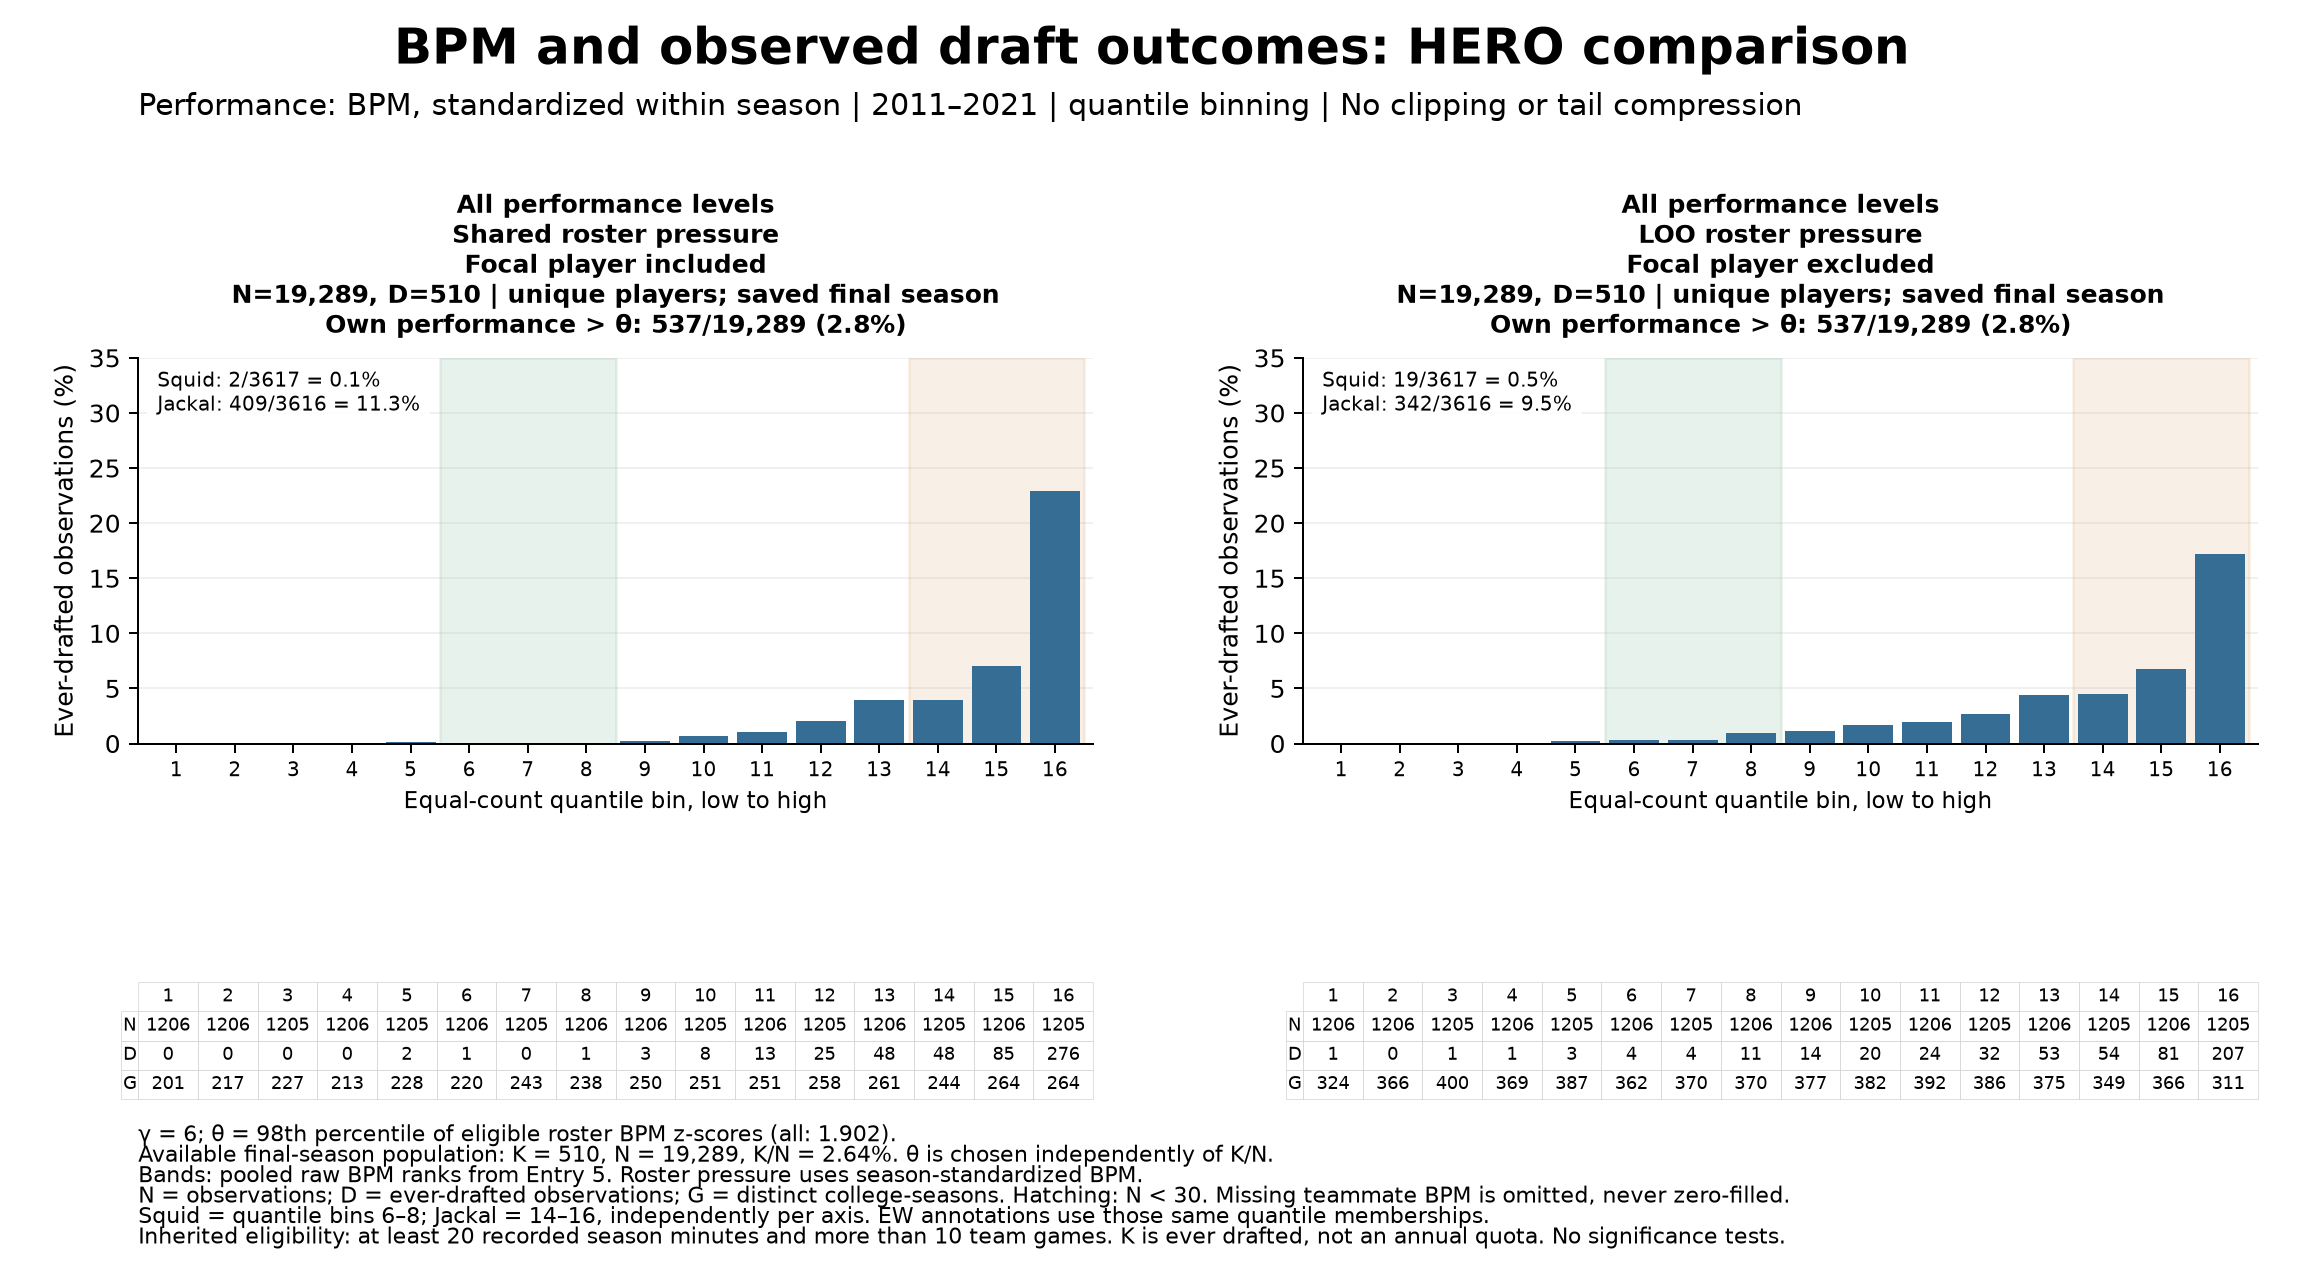

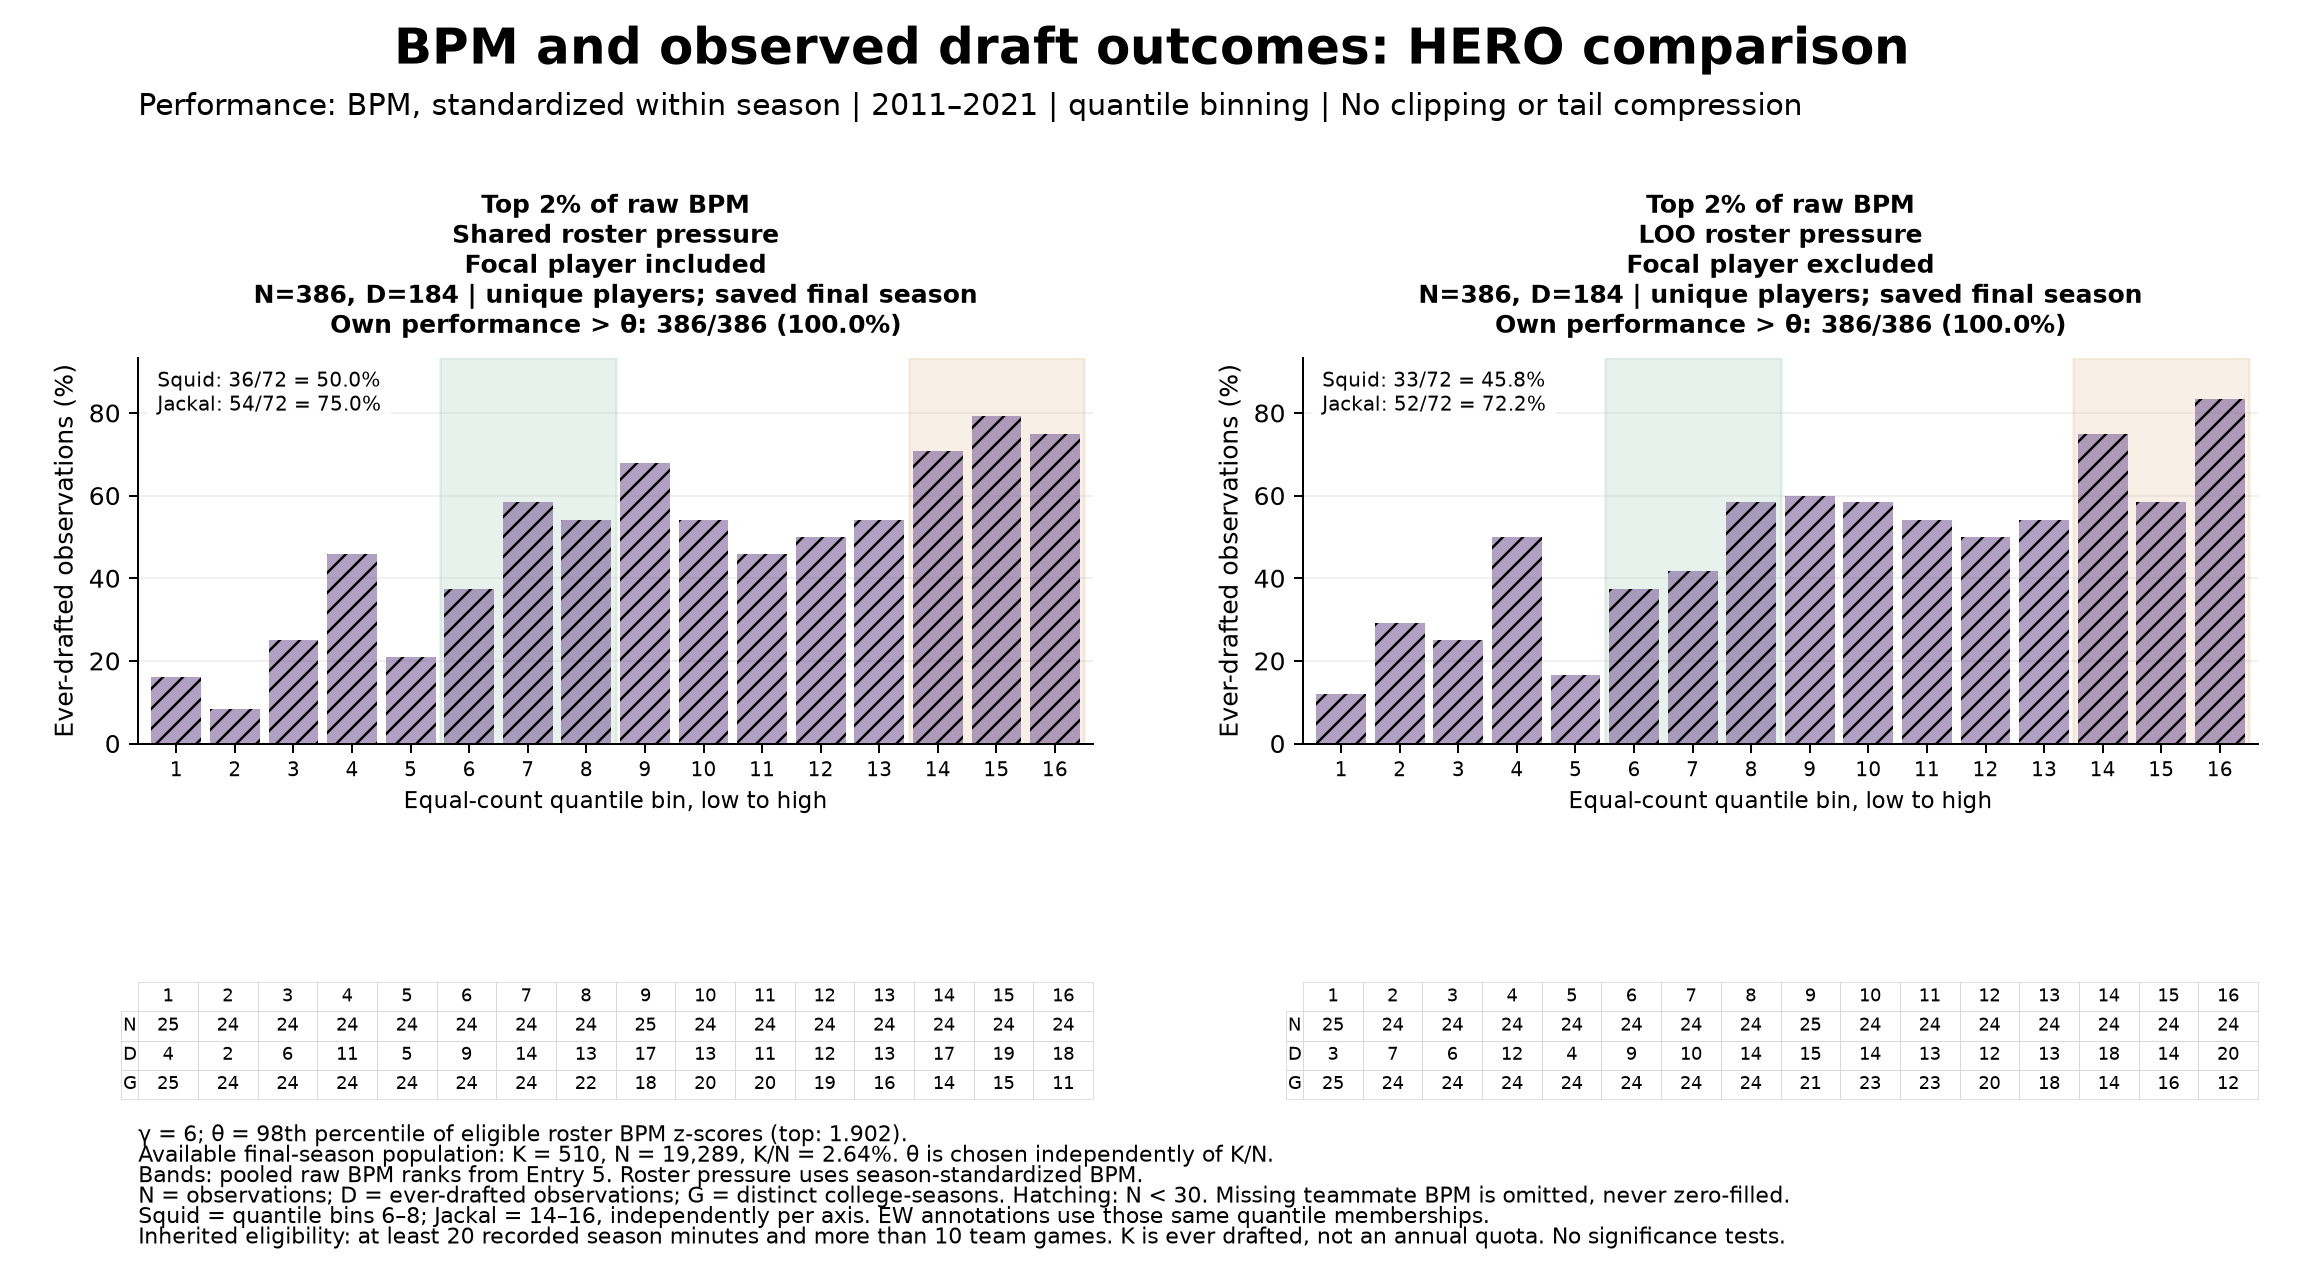

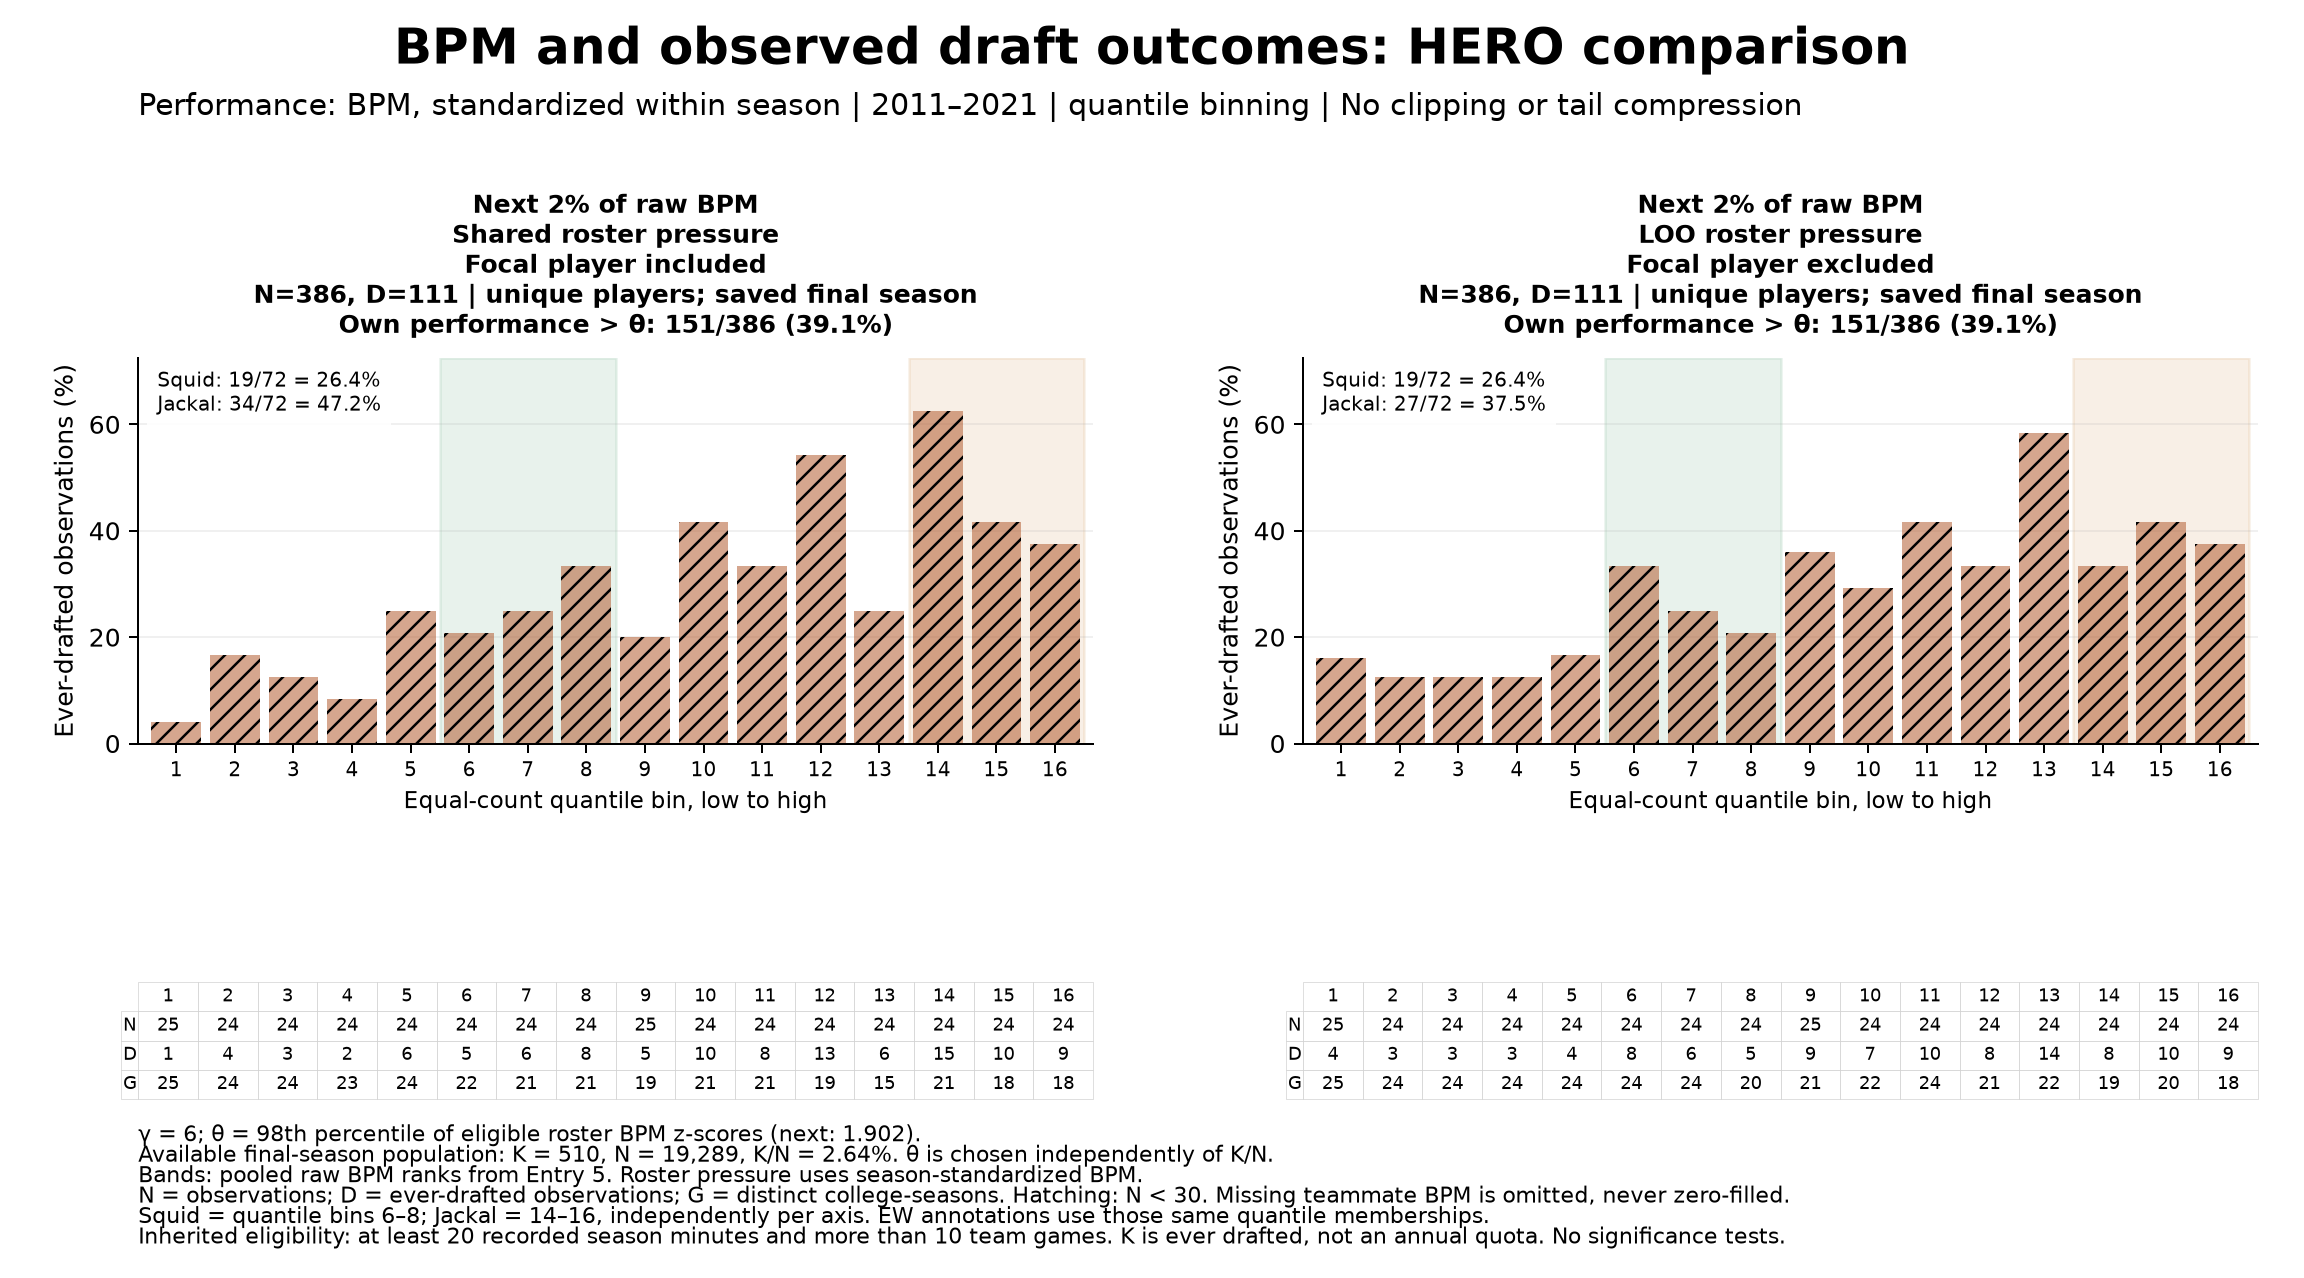

In [5]:
run = show_run_settings()
for cohort in pd.read_csv(run / "cohort_summary.csv").cohort:
    display(Image(filename=str(run / f"BPM_HERO_{cohort}_quantile.png"), width=1150))


## 5 The full quantile mosaic

The additional first column is the leave-one-out mean of season-standardized BPM. The second and third columns use shared and leave-one-out roster pressure. These are three descriptions of the same observed environment. Outcomes remain the saved ever-drafted labels; no scoring or selection simulation is being run.

DISPLAYED RUN: Top 2% and next 2% | theta percentile = 98 | gamma = 6
Run ID: 20261025_184918_282428


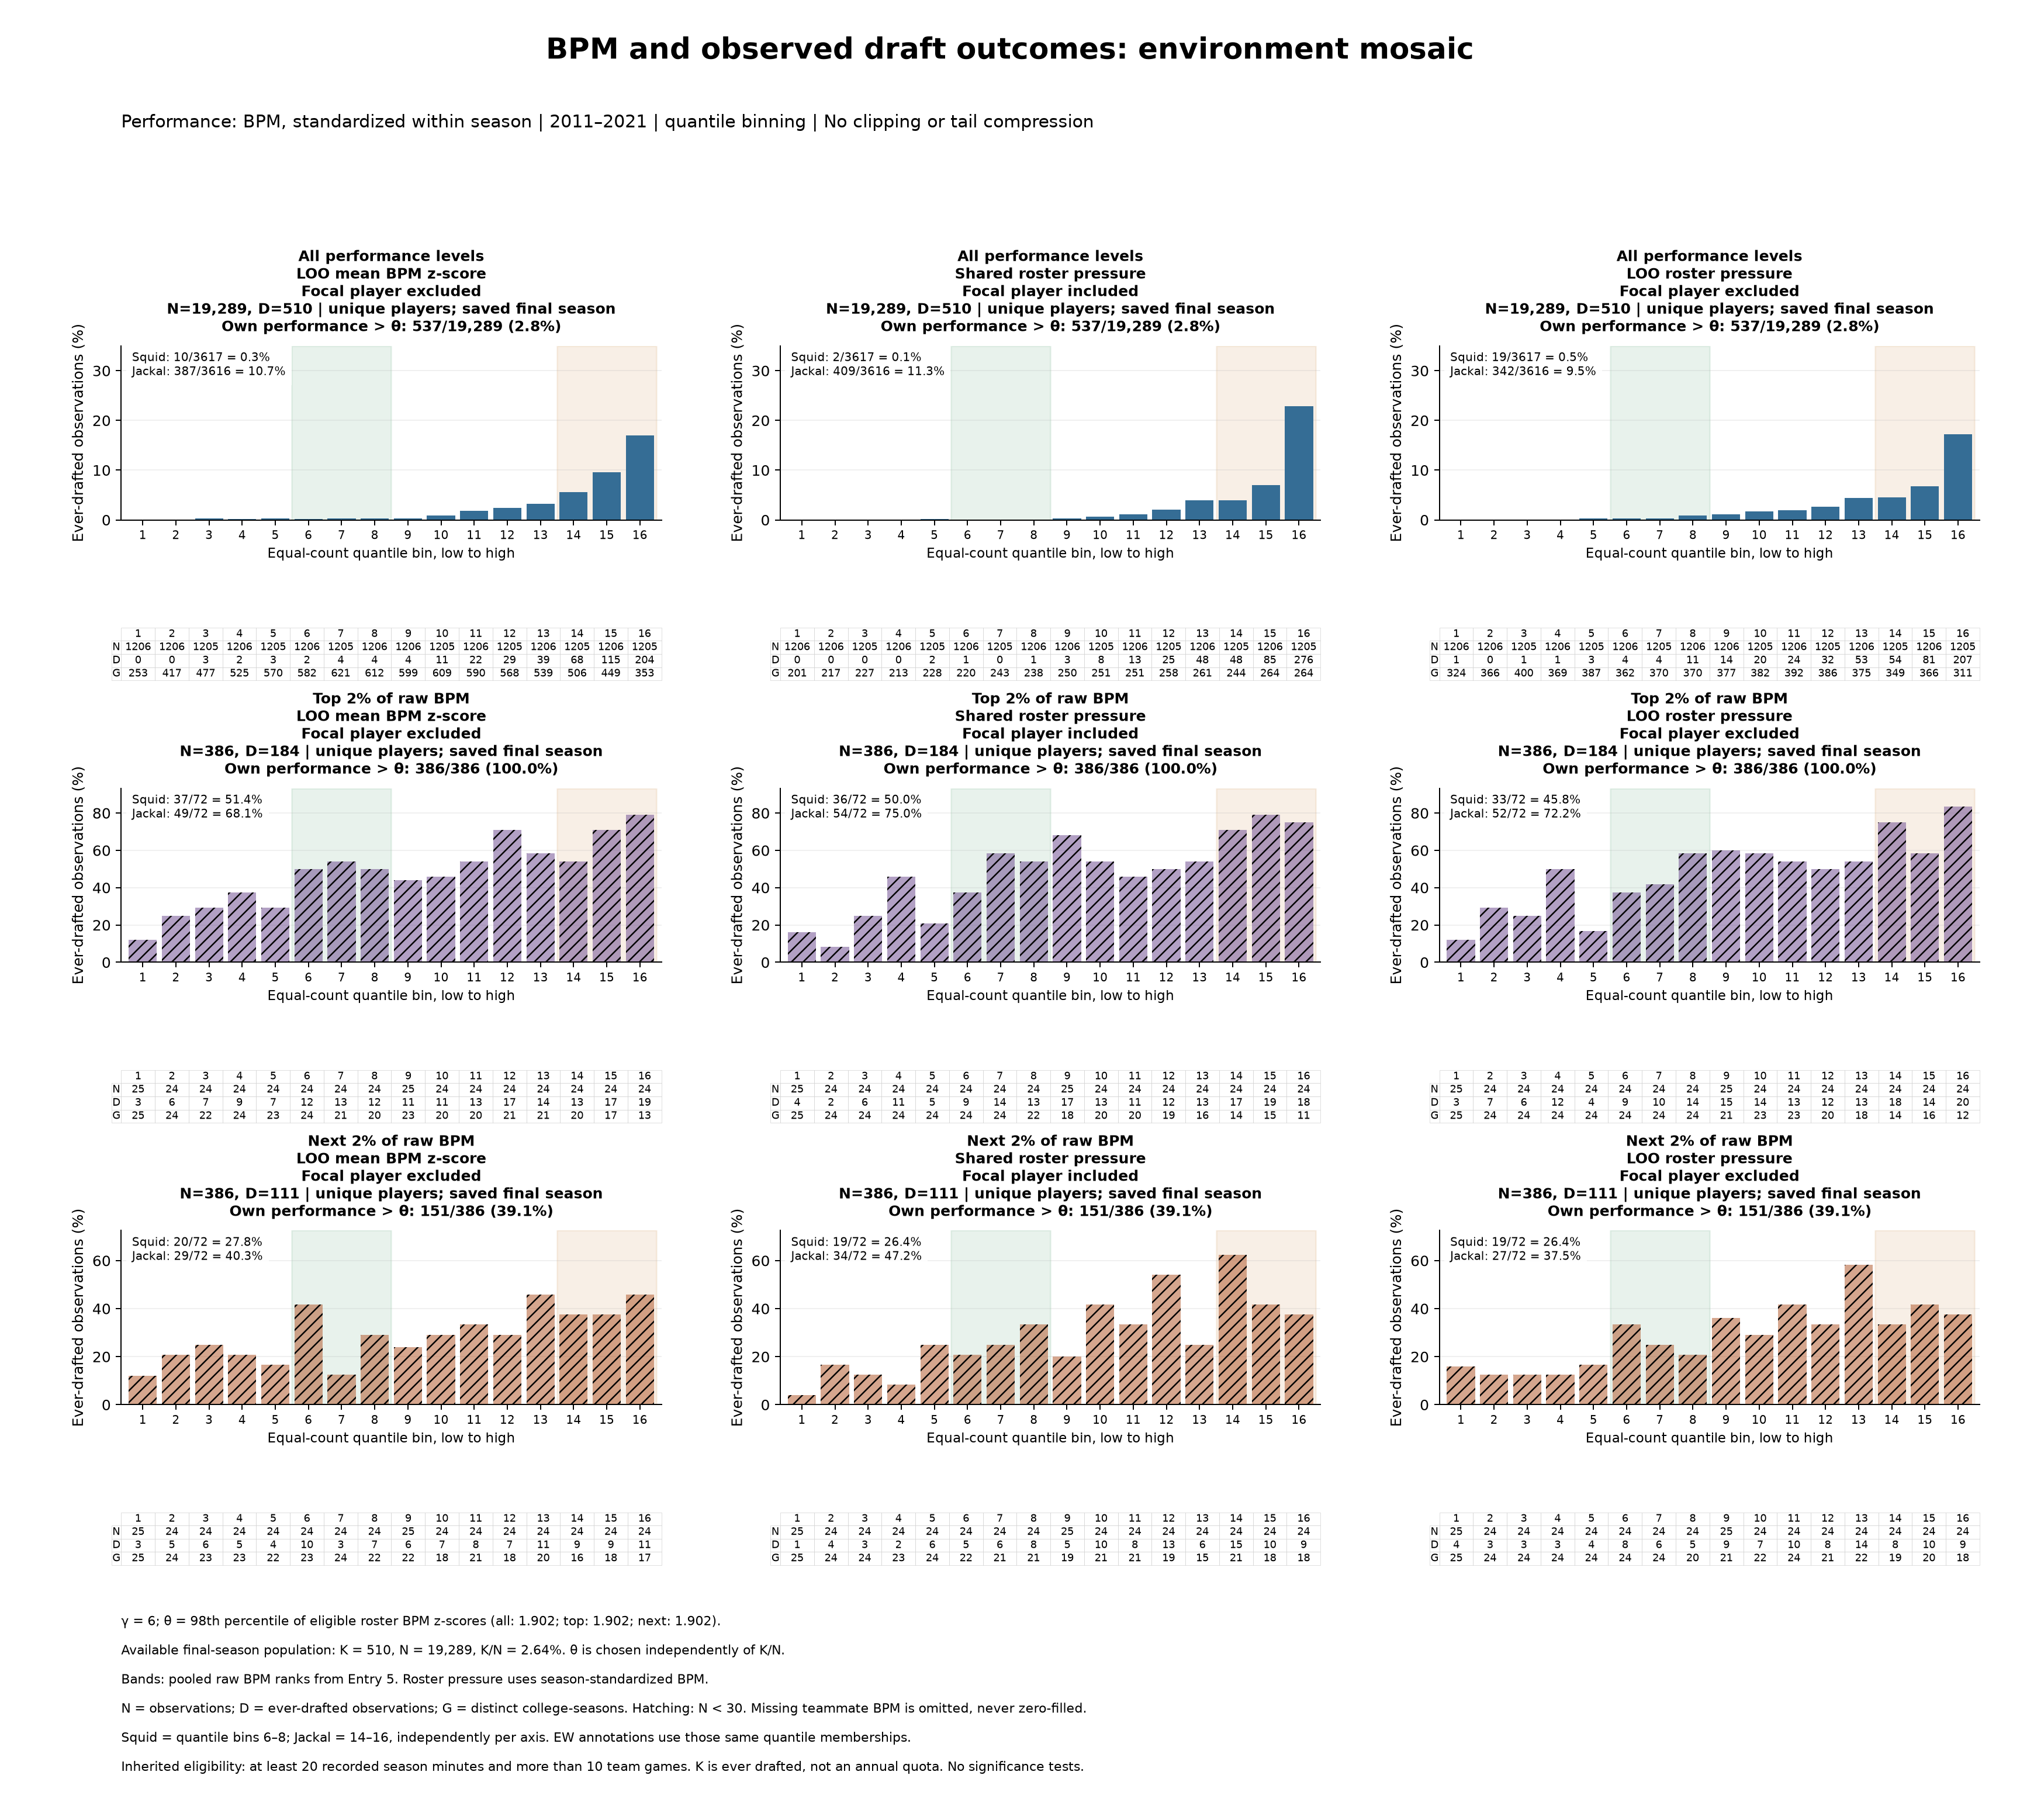

In [6]:
run = show_run_settings()
display(Image(filename=str(run / "BPM_mosaic_quantile.png"), width=1500))


## 6 Equal-width views

These bins have equal widths on each physical environmental scale, so their populations can be very unequal. Shared and LOO roster pressure use identical edges across all rows. There is no winsorization, tail compression, or hidden clipping. Extreme values therefore remain visible, and empty bins remain empty.

Squid/Jackal totals in an equal-width figure still refer to the historical quantile memberships on that axis, not to equal-width bins numbered 6–8 or 14–16.

DISPLAYED RUN: Top 2% and next 2% | theta percentile = 98 | gamma = 6
Run ID: 20261025_184918_282428


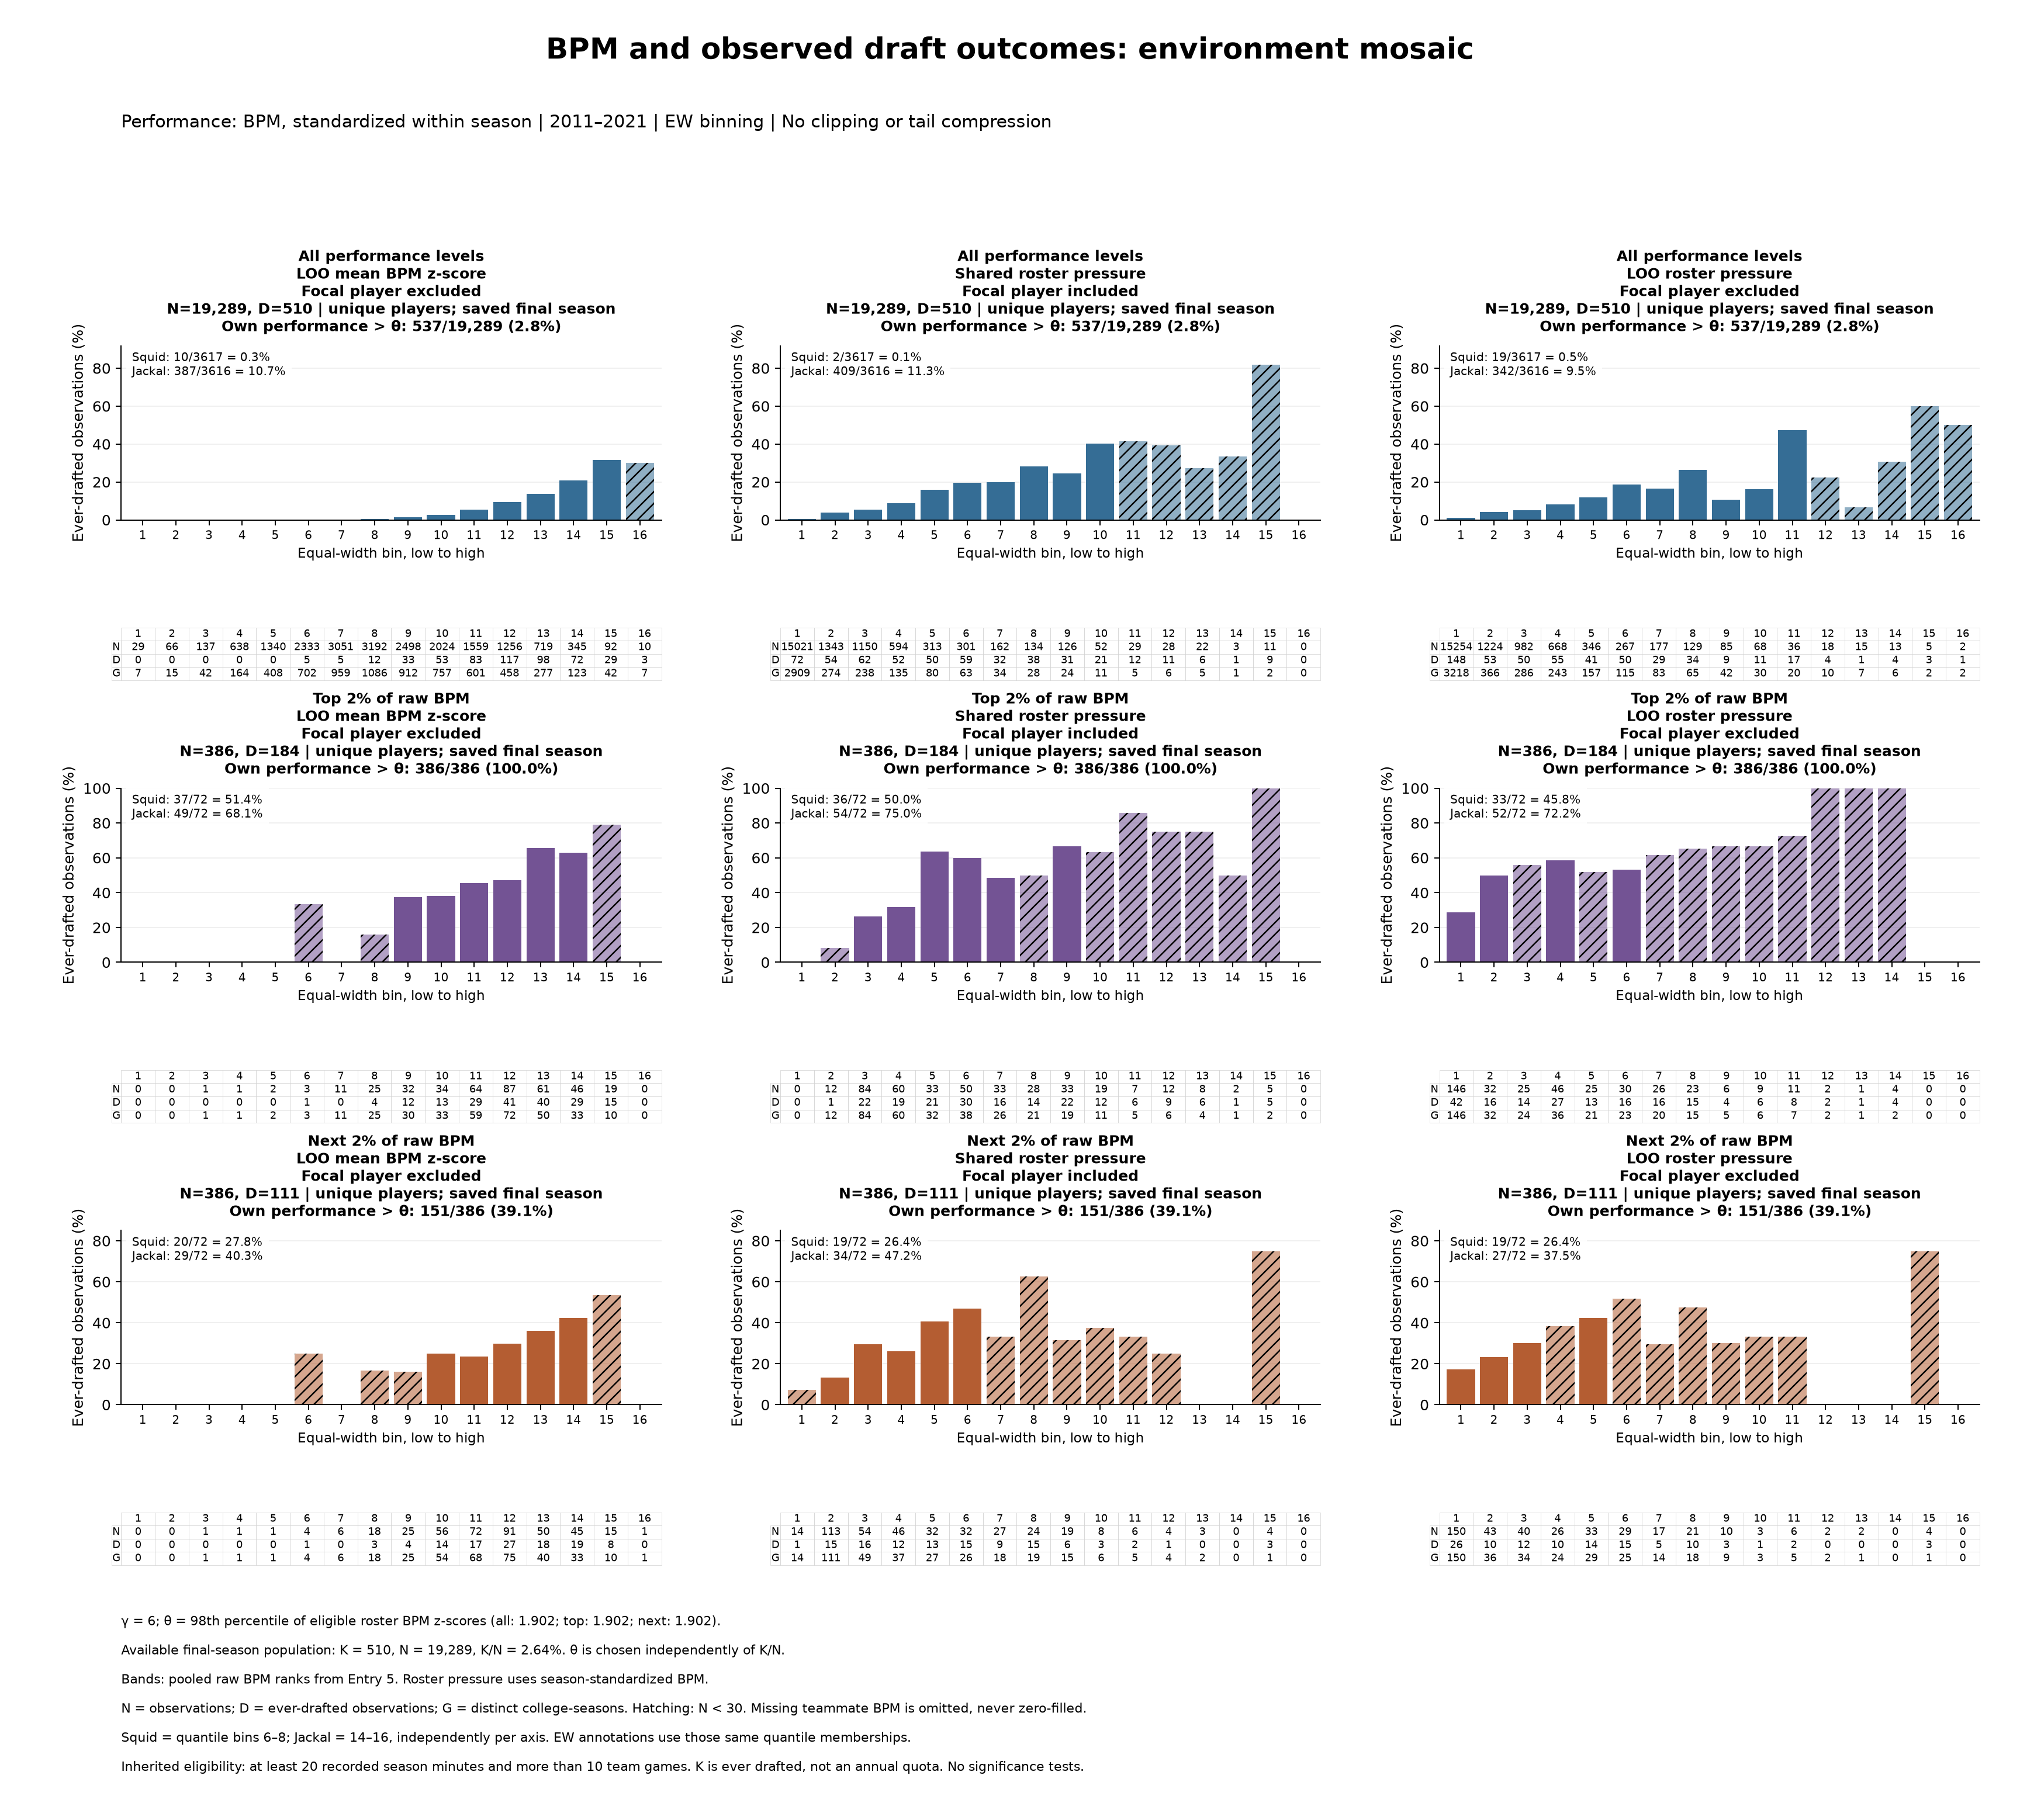

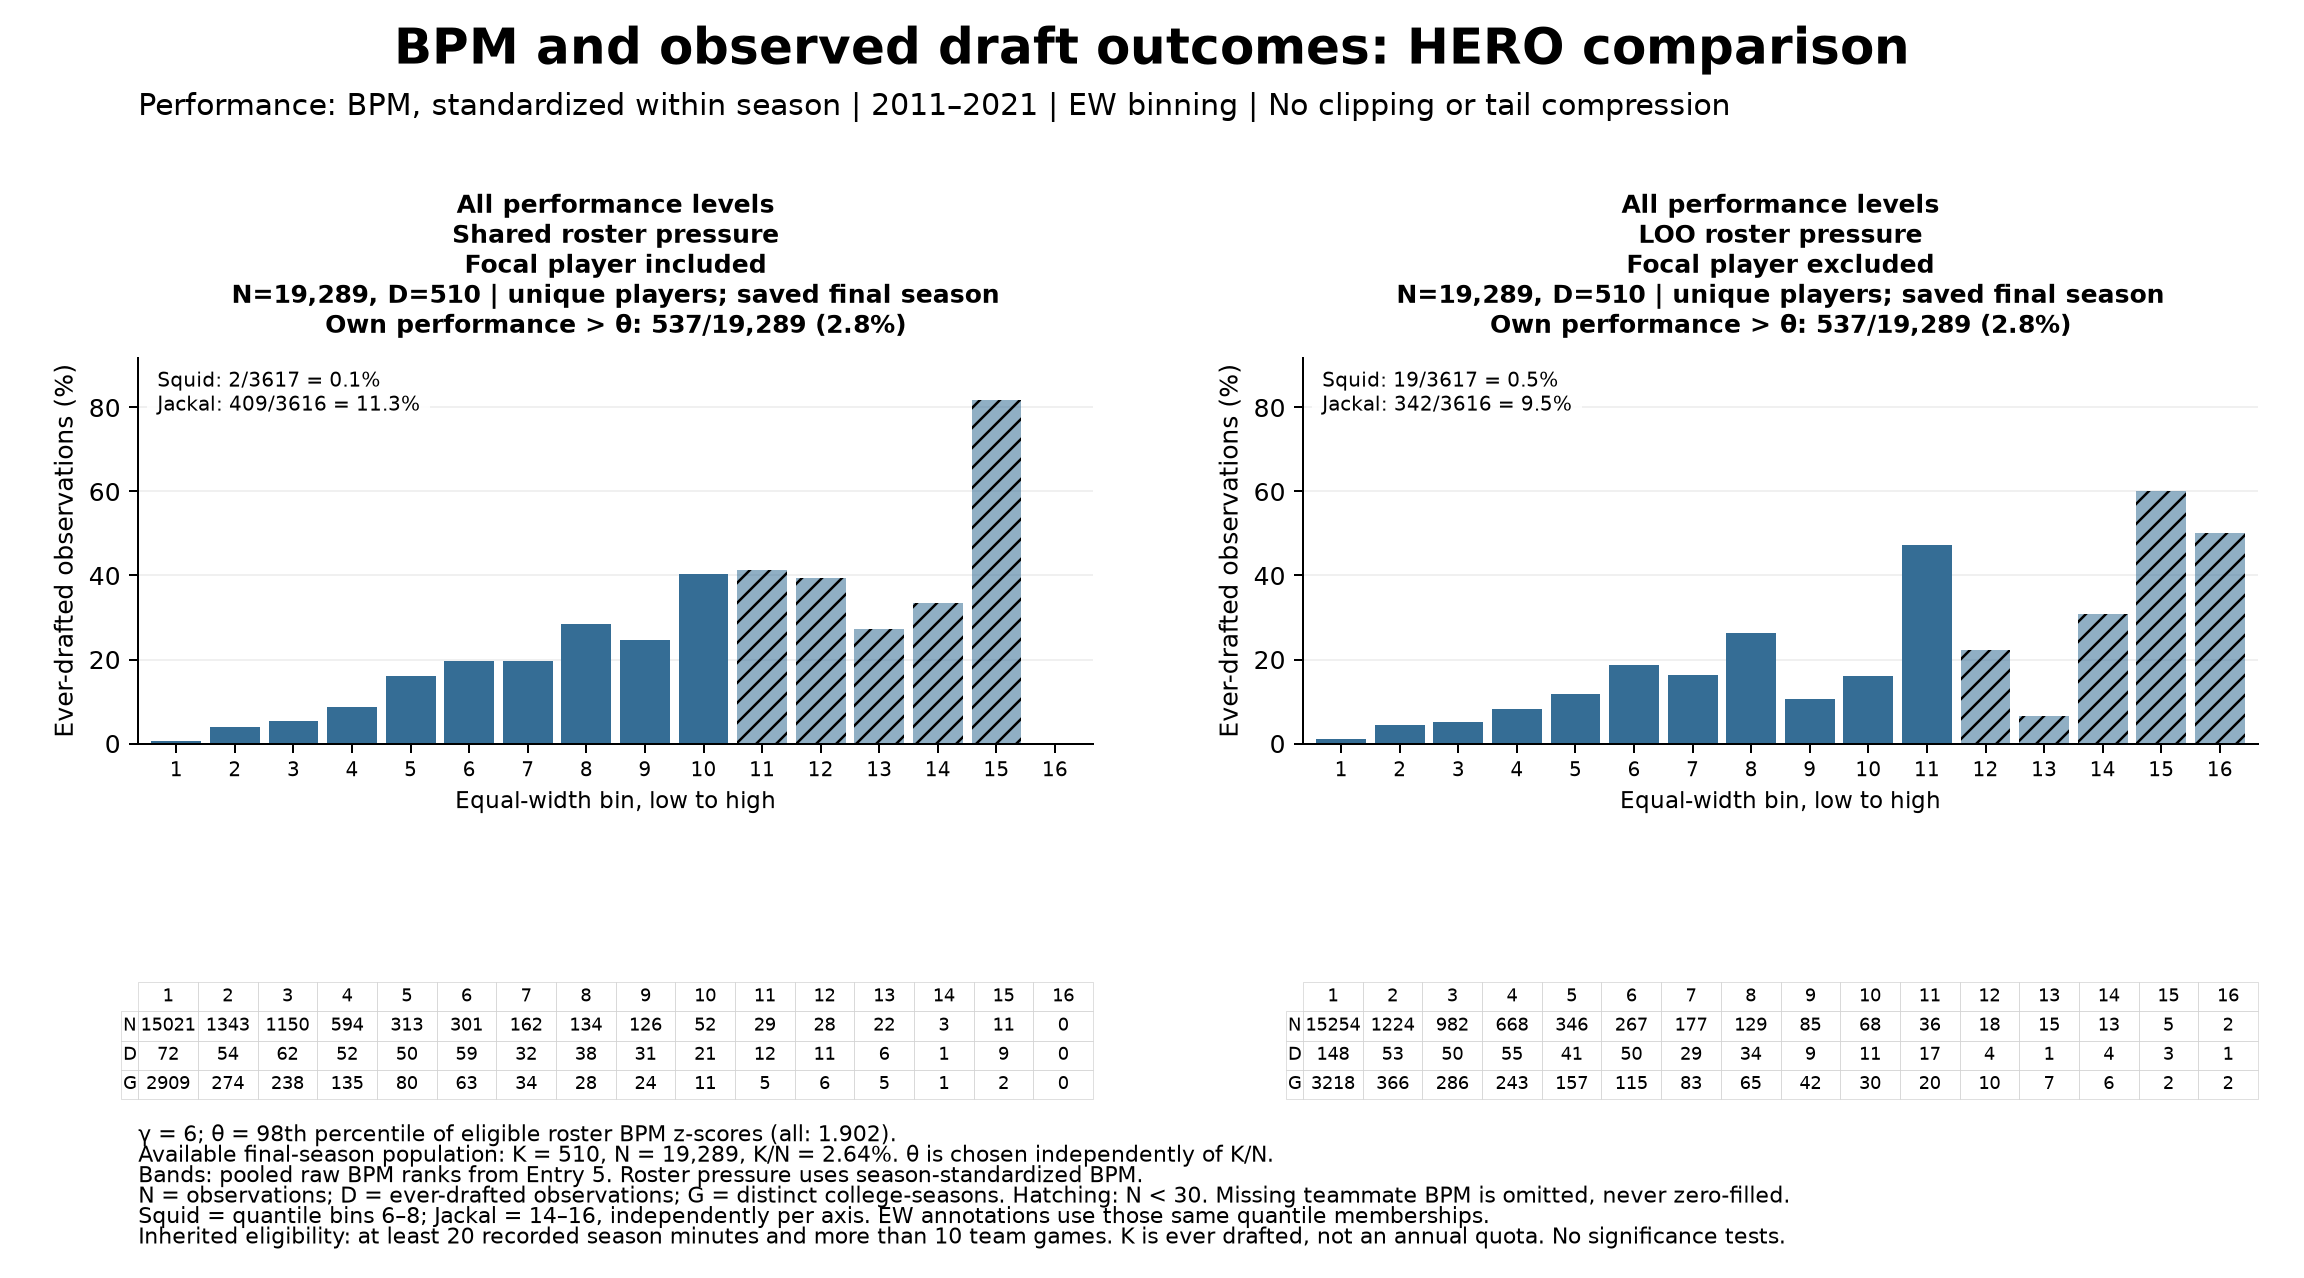

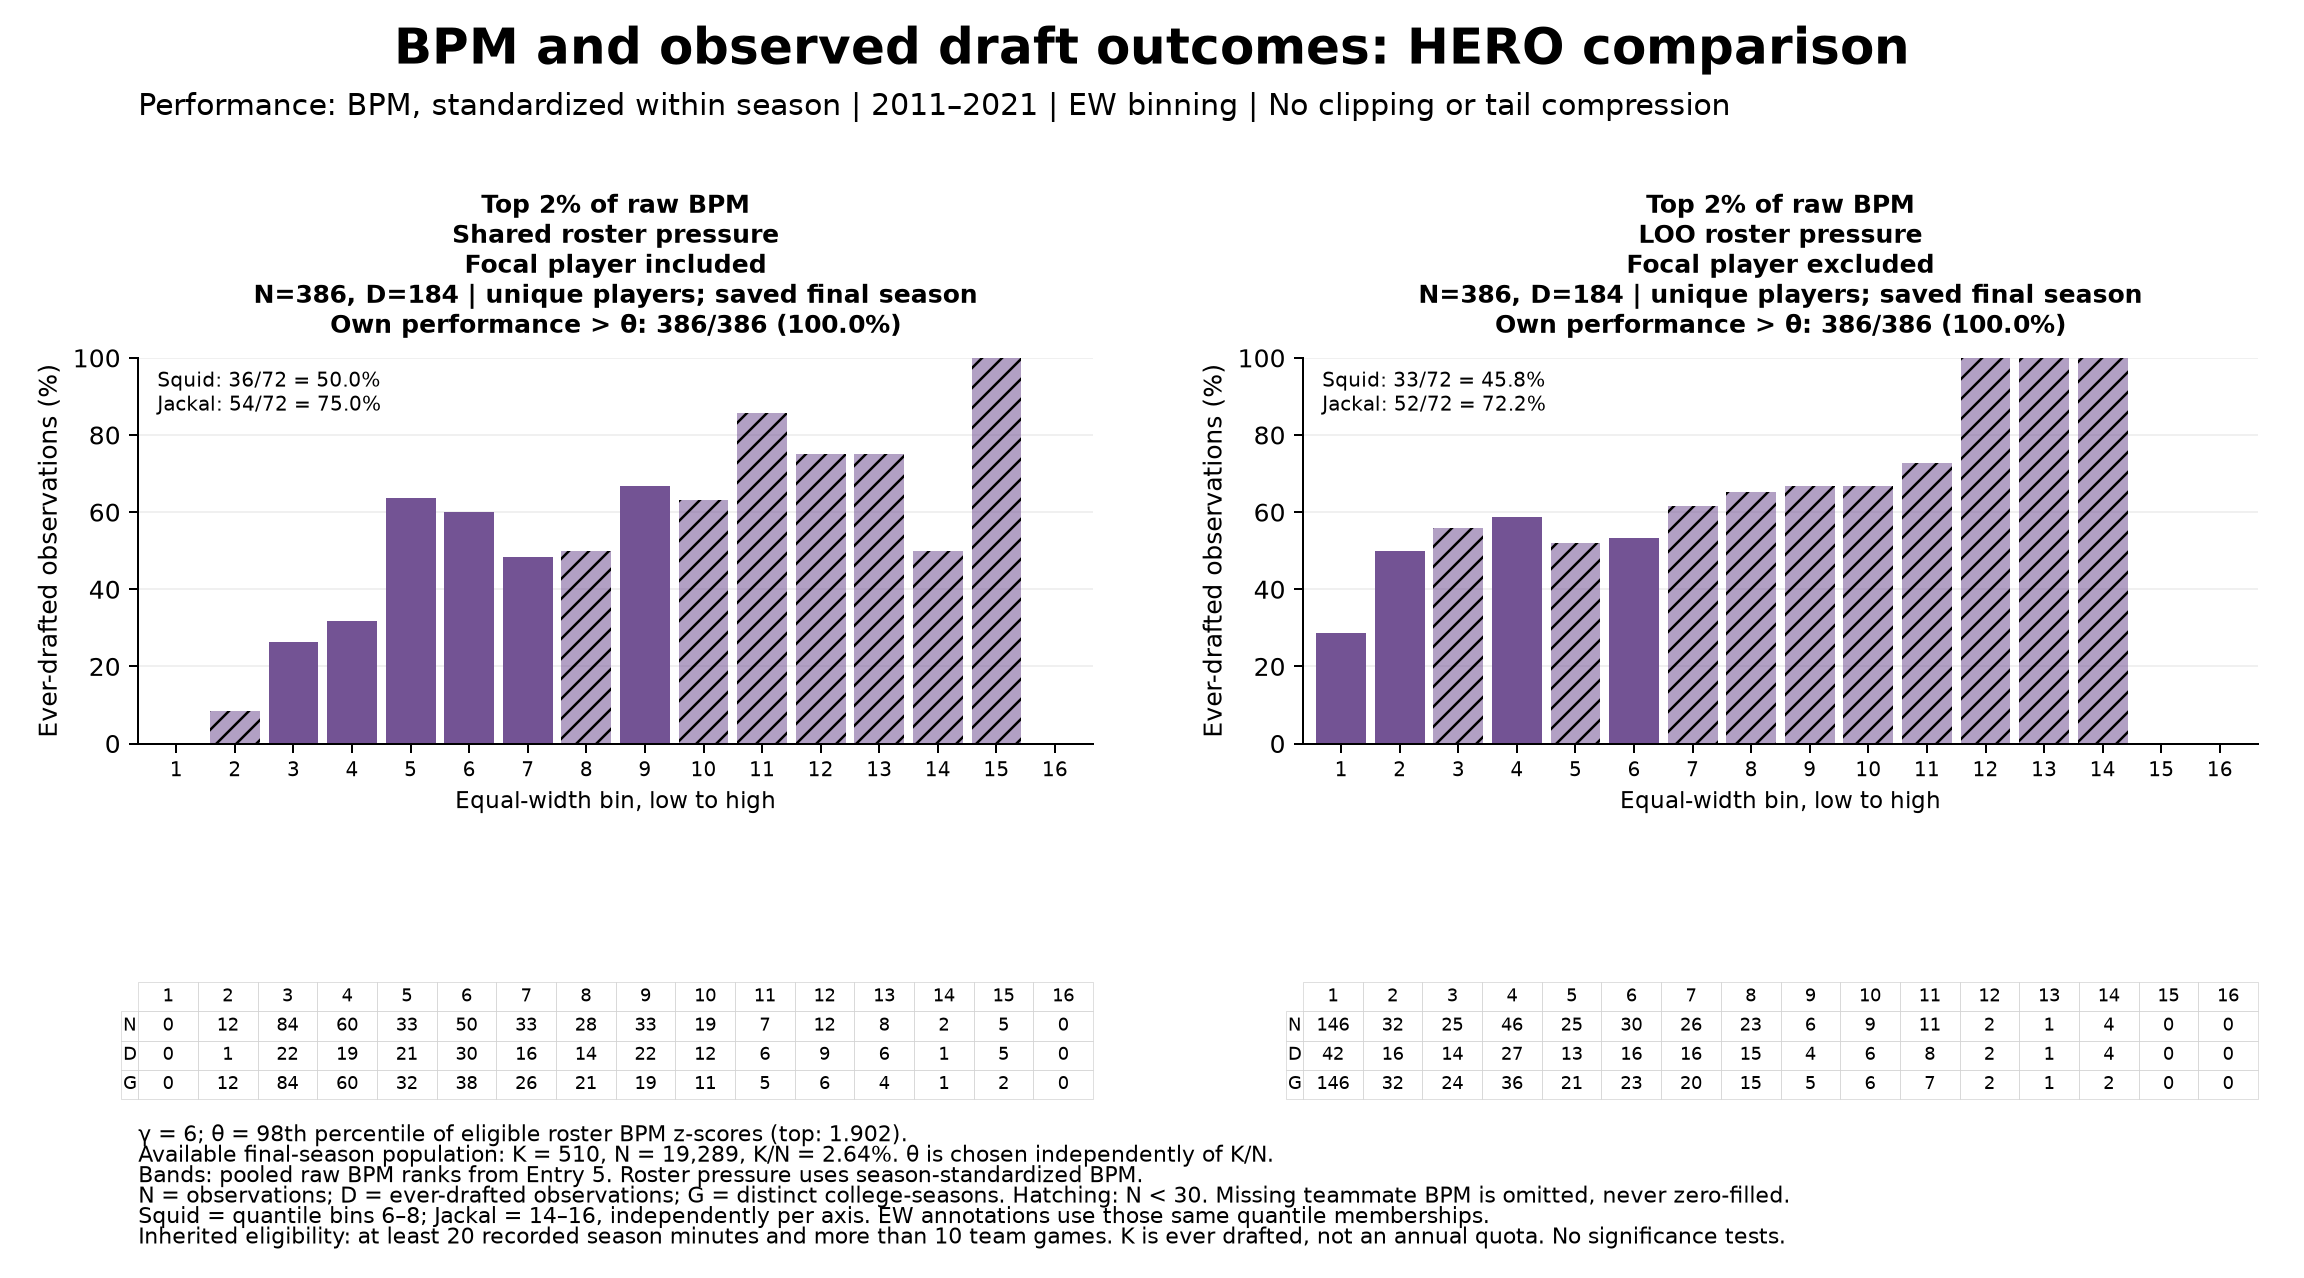

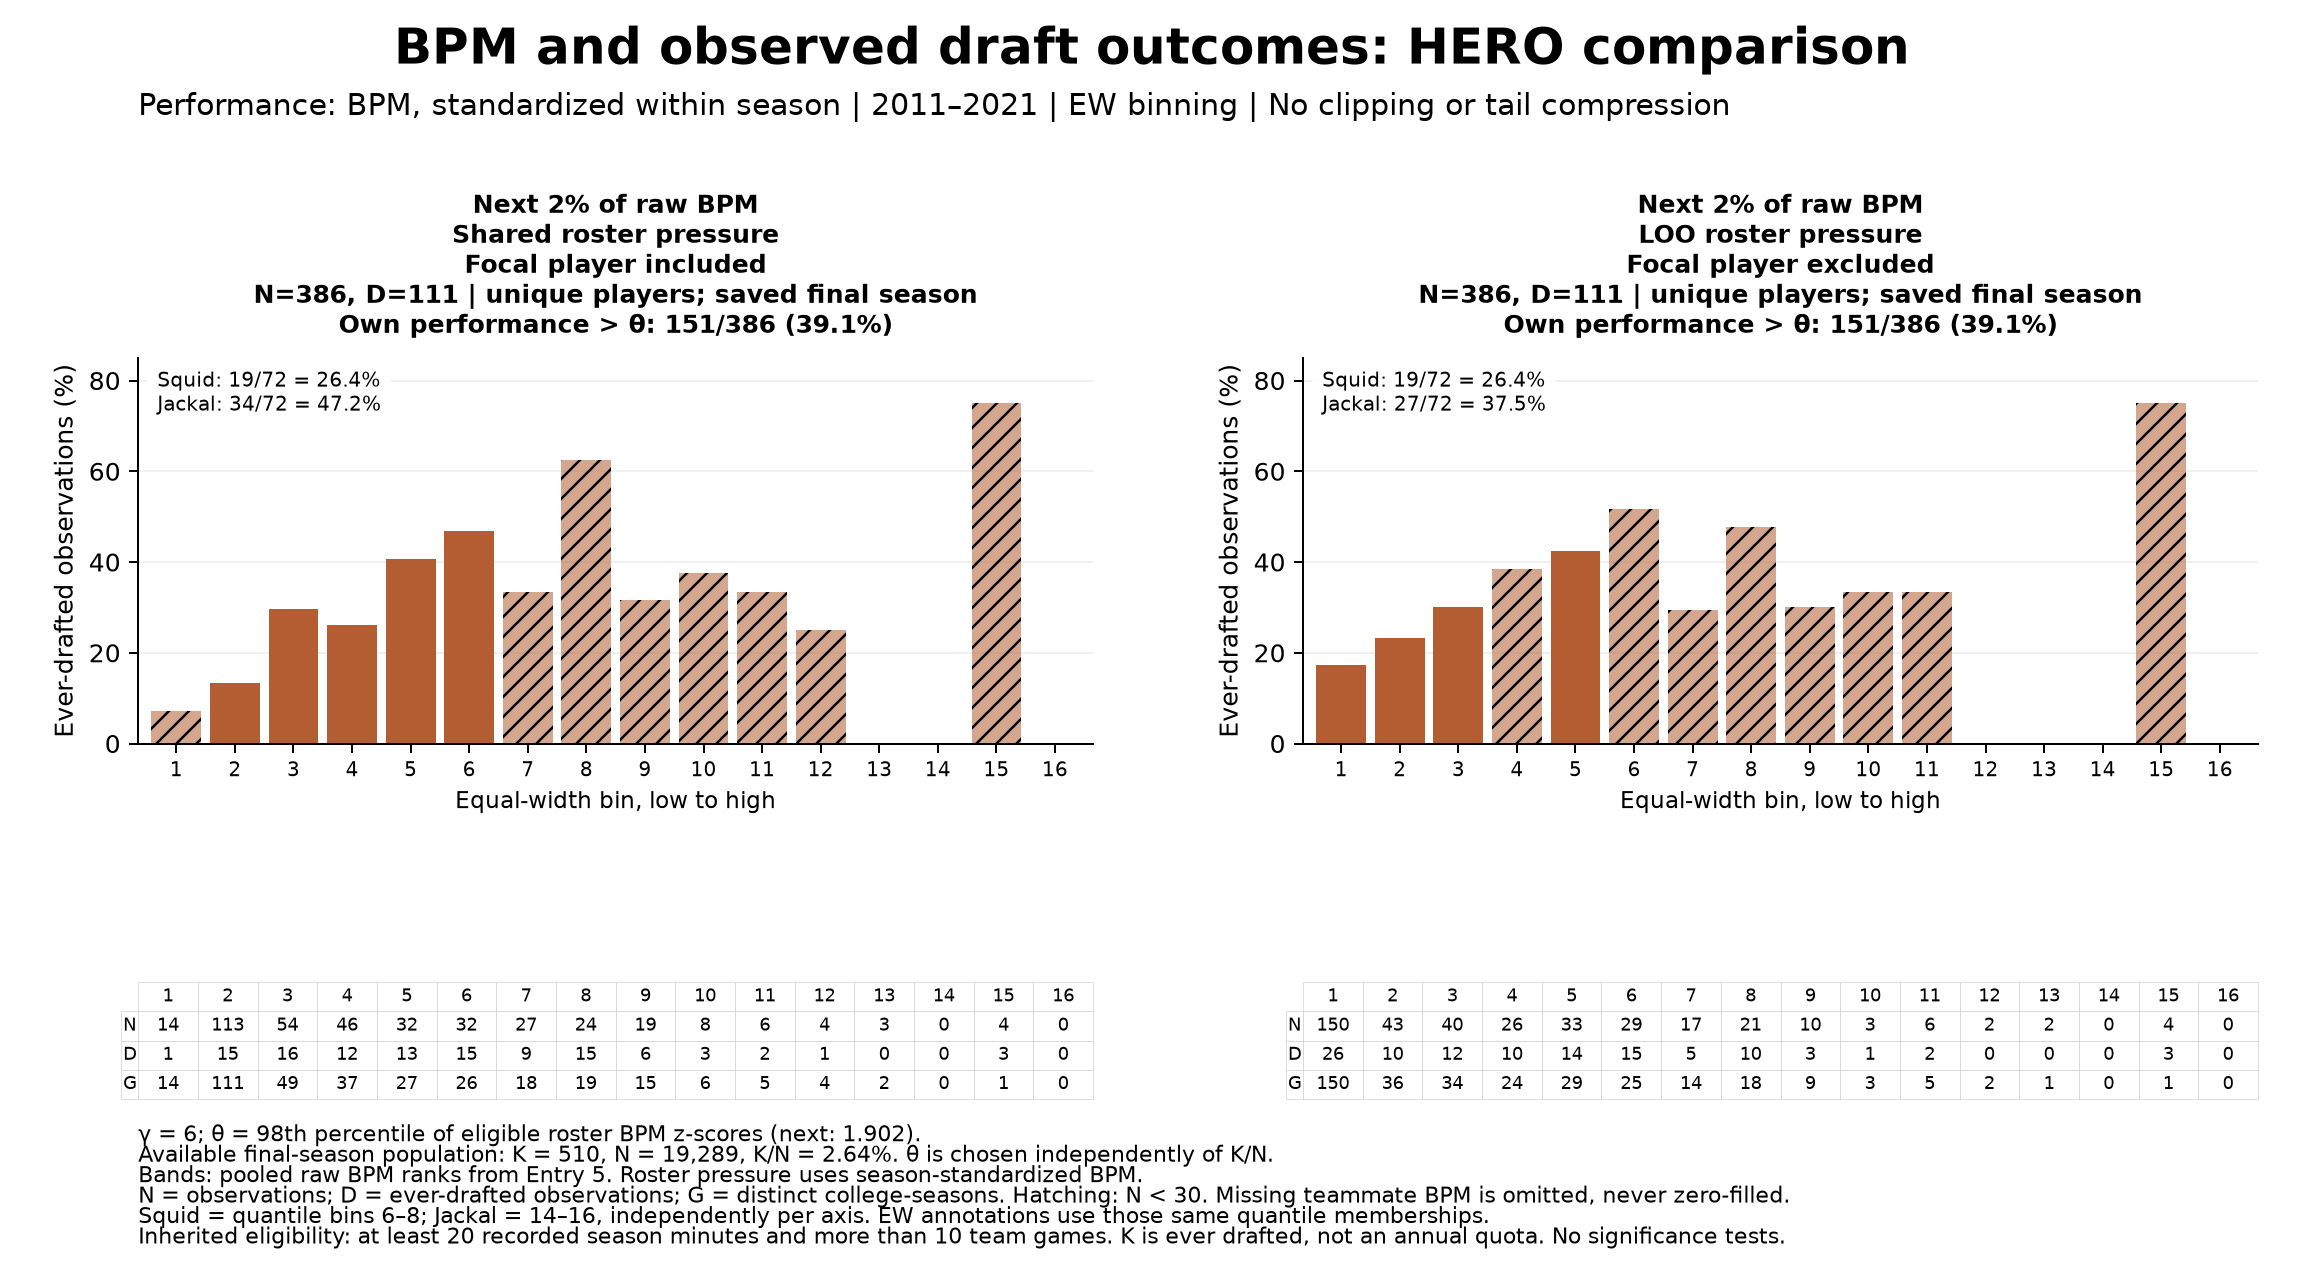

In [7]:
run = show_run_settings()
display(Image(filename=str(run / "BPM_mosaic_EW.png"), width=1500))
for cohort in pd.read_csv(run / "cohort_summary.csv").cohort:
    display(Image(filename=str(run / f"BPM_HERO_{cohort}_EW.png"), width=1150))


## 7 Inspect counts and print

Use the saved membership files to identify the players behind a bar. The narrow-band source lists retain BPM, standardized performance, minutes, college, season, competitive relevance, both pressures, and missing-teammate counts. The PDF contains both mosaics and all six HERO pairs.

Interpretation: a visible downturn is a descriptive feature to examine, not proof of congestion or statistical significance. BPM still produces extreme values for some small-minute records. We have not introduced an additional minutes threshold or chosen parameters to strengthen a downturn.

In [8]:
run = show_run_settings()
COHORT = "top" if SETTINGS["band_mode"] == "top_next" else "z2_3"
METHOD = "quantile"
counts = pd.read_csv(run / "bin_counts.csv")
display(counts.loc[(counts.cohort == COHORT) & (counts.method == METHOD)])
display(FileLink(str(run / "BPM_printable_comparisons.pdf")))


DISPLAYED RUN: Top 2% and next 2% | theta percentile = 98 | gamma = 6
Run ID: 20261025_184918_282428


,bin,n,positive_rows,rate,x,xmin,xmax,edge_left,edge_right,distinct_players,distinct_drafted_players,colleges,team_seasons,drafted_colleges,drafted_team_seasons,mean_own_performance,cohort,axis,method
48,1,25,3,0.120000,-0.442406,-1.247860e+00,-0.179019,NaN,NaN,25,3,23,25,3,3,3.017704,top,loo_performance,quantile
49,2,24,6,0.250000,-0.069082,-1.569889e-01,0.029564,NaN,NaN,24,6,22,24,5,6,2.835647,top,loo_performance,quantile
50,3,24,7,0.291667,0.122724,3.084417e-02,0.211370,NaN,NaN,24,7,22,22,6,6,2.580361,top,loo_performance,quantile
51,4,24,9,0.375000,0.296997,2.168306e-01,0.381787,NaN,NaN,24,9,21,24,8,9,2.409257,top,loo_performance,quantile
52,5,24,7,0.291667,0.456970,3.826248e-01,0.540068,NaN,NaN,24,7,20,23,6,6,2.462175,top,loo_performance,quantile
53,6,24,12,0.500000,0.584931,5.462831e-01,0.616252,NaN,NaN,24,12,22,24,12,12,2.320965,top,loo_performance,quantile
54,7,24,13,0.541667,0.643009,6.196274e-01,0.672868,NaN,NaN,24,13,19,21,10,11,2.412790,top,loo_performance,quantile
55,8,24,12,0.500000,0.722931,6.737478e-01,0.753357,NaN,NaN,24,12,17,20,11,11,2.360008,top,loo_performance,quantile
56,9,25,11,0.440000,0.782852,7.540388e-01,0.817877,NaN,NaN,25,11,20,23,11,11,2.408113,top,loo_performance,quantile
57,10,24,11,0.458333,0.845863,8.210049e-01,0.874676,NaN,NaN,24,11,18,20,9,10,2.322207,top,loo_performance,quantile


/Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/roster_pressure_comparison/bpm_runs/20261025_184918_282428/BPM_printable_comparisons.pdf